# Benchmarking a qubit: T1, T2*, and T2

## The problem

Every circuit in this course runs against a clock. A qubit is a physical object that is slowly losing what we stored in it, and the longer a circuit takes, the more is lost. Before running anything on a device, ask how long a qubit keeps its state. Three numbers answer that, and they are the first entries on the calibration page of any quantum computer, including `ibm_rensselaer`.

Recall the two things a qubit holds: a **bit** (is it $|0\rangle$ or $|1\rangle$?) and a **phase** (the relative angle between the amplitudes of $|0\rangle$ and $|1\rangle$, which is what interference uses). Each can be lost:

- **T1, relaxation time.** A qubit in $|1\rangle$ is at higher energy than one in $|0\rangle$, and it eventually falls to $|0\rangle$. The stored bit flips by itself. T1 is the time scale of that flip.
- **T2\*, dephasing time seen by a Ramsey experiment** (prepare a superposition, wait, and measure its phase)**.** A qubit in a superposition has a phase, and the phase advances at the qubit's frequency. If the frequency wanders, a little differently every run, the phases of many runs spread apart and the average phase is lost. The bit is fine; the *superposition* is not.
- **T2, dephasing time after an echo.** Much of that wandering is slow: constant during one run, different from run to run. A single well-placed bit flip in the middle of the wait cancels everything that is constant. What an echo cannot cancel is the fast noise, and T2 is its time scale. Always $T_2^* \le T_2 \le 2\,T_1$.

All three are measured the same way: prepare a state, wait for a delay $t$, measure one observable, and repeat for many delays. The result is a decay curve, and **the time is a fit parameter**. This notebook is about the fit as much as the measurement.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | The observable each experiment measures, and the decay model we fit | `ops.py` |
| 2. Encoding | Build the delay circuits and round delays to what the hardware can run | `encoding.py` |
| 3. Execution | Run every delay of every experiment as one job | `execution.py` |
| 4. Analysis | Fit the curves, plot the fits, read off the times | `analysis.py` |

The same steps run from the command line with `python benchmarking/main.py`, started in `../scripts/`. The code lives in `../scripts/benchmarking/` and is imported below, so each module can be read next to the step that uses it. Times are in microseconds.

## Setup

By default this notebook runs on the Aer simulator with noise that we chose: $T_1 = 100\,\mu$s, $T_2 = 70\,\mu$s, a slow frequency noise that makes $T_2^*$ shorter, and a 2-4% read-out error. Because we know the answers, we can check the fits against them. Set `backend_name = "ibm_rensselaer"` to measure a real qubit instead.

- `qubit`: the physical qubit to measure on hardware. Ignored on the simulator.
- `points`: delays per experiment. More points give a better fit and cost more circuits.
- `precision`: target standard error of each expectation value. It sets the shots on hardware, and the size of the added noise on the simulator.
- `t_max`: the longest delay of each experiment. A good range runs to about **three decay times**. On hardware you do not know the times before you measure them, so run once with a wide range, read the fit, and run again with the range centered on the answer.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Statevector

# The benchmarking code lives in ../scripts/benchmarking.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/benchmarking").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

backend_name = None  # None = Aer simulator, or e.g. "ibm_rensselaer"
qubit = 0  # physical qubit, hardware only
points = 41
precision = 0.02
t_max = {"t1": 300.0, "t2star": 120.0, "t2": 200.0}  # microseconds

## Step 1: The operator (what we measure)

### The observable

The Estimator returns the **expectation value** $\langle O\rangle$ of an operator $O$: the average of the answer $\pm1$ over many runs. The two operators we need are the ones that read the two things a qubit holds.

- $Z$ reads the **bit**. $\langle Z\rangle = P(0) - P(1)$, so it is $+1$ for $|0\rangle$ and $-1$ for $|1\rangle$.
- $X$ reads the **phase**. For a state $(|0\rangle + e^{i\varphi}|1\rangle)/\sqrt2$ it gives $\langle X\rangle = \cos\varphi$. It is $+1$ when the two amplitudes are in phase and $0$ when the phase has been scrambled completely.

| Experiment | Prepare | Wait | Measure | Expected curve |
|---|---|---|---|---|
| T1 | $\lvert1\rangle$ | $t$ | $Z$ | $-1 \to +1$, $\;e^{-t/T_1}$ |
| T2\* (Ramsey) | $\lvert+\rangle = (\lvert0\rangle+\lvert1\rangle)/\sqrt2$ | $t$, then a phase of $2\pi f t$ | $X$ | $\cos(2\pi f t)\,e^{-t/T_2^*}$ |
| T2 (Hahn echo) | $\lvert+\rangle$ | $t/2$, flip, $t/2$ | $X$ | $e^{-t/T_2}$ |

A check on a noiseless statevector shows that the observables read what we said.

In [2]:
from qiskit import QuantumCircuit

def expectation(circuit, name):
    return Statevector(circuit).expectation_value(ops.observable(name)).real

zero = QuantumCircuit(1)
one = QuantumCircuit(1); one.x(0)
plus = QuantumCircuit(1); plus.h(0)
quarter = QuantumCircuit(1); quarter.h(0); quarter.rz(np.pi / 2, 0)  # phase of 90 degrees
half = QuantumCircuit(1); half.h(0); half.rz(np.pi, 0)  # phase of 180 degrees

print(f"{'state':<26} {'<Z>':>6} {'<X>':>6}")
for label, c in [("|0>", zero), ("|1>", one), ("|+>", plus),
                 ("|+> with phase 90 deg", quarter), ("|+> with phase 180 deg", half)]:
    print(f"{label:<26} {expectation(c, 't1'):>6.2f} {expectation(c, 't2star'):>6.2f}")

state                         <Z>    <X>
|0>                          1.00   0.00
|1>                         -1.00   0.00
|+>                          0.00   1.00
|+> with phase 90 deg        0.00   0.00
|+> with phase 180 deg       0.00  -1.00


Notice that $\langle Z\rangle$ is blind to the phase and $\langle X\rangle$ is blind to the bit of $|0\rangle$ and $|1\rangle$. That is why T1 needs $Z$ and the two dephasing times need $X$.

### The decay model

The curves are exponentials, because the loss in each short interval is proportional to what is left. We fit

$$\langle O\rangle(t) = A\,e^{-t/\tau} + B \quad\text{(T1 and T2)}, \qquad \langle X\rangle(t) = A\,e^{-t/\tau}\cos(2\pi f t + \phi) + B \quad\text{(T2*)}.$$

The time constant $\tau$ is the one we want: after one $\tau$ the decaying part has fallen to $1/e \approx 37\%$ of its start. $A$ and $B$ are **nuisance parameters**. In an ideal experiment $B$ is the final value ($+1$ for T1, $0$ for the others) and $A$ is the size of the swing ($-2$ for T1, $+1$ for the others). A real device prepares and reads imperfectly, so $A$ and $B$ come out a little different, and fitting them keeps those errors out of $\tau$. $f$ and $\phi$ are the Ramsey detuning (a frequency offset that we program on purpose, explained below) and the starting phase.

## Stop and think: why do we need a detuning?

1. **We make the Ramsey signal oscillate on purpose.** The oscillations are called fringes. Without them, $\langle X\rangle$ would only decay, and a slow decay of the phase would look the same as a state preparation that did not quite reach $|+\rangle$. A fringe at a frequency we chose can only come from phase that evolves, so the decay of the envelope can be trusted.
2. **The fringe frequency is a measurement too.** We program $f = 50$ kHz in software, a rotation about $Z$ by $2\pi f t$ after the wait. If the fit returns a different $f$, the qubit's own frequency is off from the one the control electronics assume by the difference. Step 4 prints it.
3. **The echo has no detuning.** The flip in the middle reverses the sign of any phase collected so far, so anything constant cancels, including a detuning we programmed. The echo curve is a pure decay.
4. **Three different times, three different noises.** T1 sees energy flowing out. T2\* sees the energy flow, the fast noise, and the slow drifts. T2 sees the first two only. Comparing the three tells you which kind of noise limits the qubit.

## Step 2: Encoding

### Delay circuits

Each circuit prepares the state in the table above and then waits. The wait is a `Delay` instruction: the qubit idles while the clock runs. Nothing is measured in the circuit, because the observable is passed to the Estimator separately.

Delays are counted in **dt**, the sample time of the control electronics, and must be a multiple of a **granularity** (16 dt on IBM devices). The function `snap` rounds each requested delay to the closest allowed one and returns the delay that was actually run. We fit against the delays that were actually run, not the ones we asked for.

In [3]:
backend, _ = execution.get_primitives(backend_name)
dt, granularity = enc.timing(backend)
print(f"dt = {dt * 1e9:.4f} ns, delays are a multiple of {granularity} dt = {granularity * dt * 1e6:.4f} us")

requested = ops.delay_grid(t_max["t2"], points)
waits, actual = enc.snap(requested, dt, granularity, parts=2)  # an echo has two waits
print("\nrequested (us):", np.round(requested[:5], 3))
print("actual    (us):", np.round(actual[:5], 3))
print("wait (dt, each half):", waits[:5])

dt = 0.2222 ns, delays are a multiple of 16 dt = 0.0036 us

requested (us): [ 0.  5. 10. 15. 20.]
actual    (us): [ 0.     4.999  9.998 14.997 20.003]
wait (dt, each half): [    0 11248 22496 33744 45008]


T1 (relaxation) (measure Z):


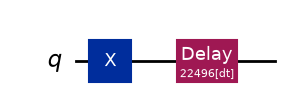

T2* (Ramsey) (measure X):


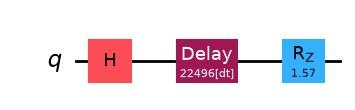

T2 (Hahn echo) (measure X):


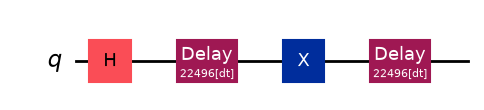

In [4]:
wait = int(5e-6 / dt) // granularity * granularity  # a wait of about 5 us
for name in ops.EXPERIMENTS:
    print(ops.NAMES[name], f"(measure {ops.OBSERVABLES[name]}):")
    fig = enc.build_circuit(name, wait, dt).draw("mpl")
    display(fig)
    plt.close(fig)  # keep the inline backend from drawing it a second time

The Ramsey circuit carries the programmed rotation `rz`, and the echo circuit has a flip `x` between two equal delays. The circuits are compiled with the optimizer **off** (`transpile_for`). An optimizer is allowed to rewrite a circuit into a shorter one that does the same thing, and "flip, wait, flip back" is what it is built to remove. It would delete the very thing we want to measure.

## Stop and think: what did the encoding decide?

1. **The delay is the only thing that varies.** All the circuits of one experiment are identical except for the wait. A curve measured this way is a clean function of $t$.
2. **The echo uses half the delay in each wait.** The total time of the echo is $t$, so its curve is comparable with the others. That is why `snap` takes `parts=2`.
3. **Hardware has its own tools for the echo.** The Estimator on IBM devices can insert **dynamical decoupling** pulses into idle times automatically. That is the same idea as the echo, applied everywhere. We switch it off, because here the idle time is the thing being measured.

## Step 3: Execution

Every delay of every experiment is one circuit, so three experiments of `points` delays each make a few hundred circuits. They go out as **one job**: on hardware the queue wait is paid once per job, not once per circuit.

On the simulator, the noise is added in three places:

1. every delay relaxes with the chosen $T_1$ and $T_2$;
2. the read-out flips the answer 2% or 4% of the time, depending on the state, which is what makes $A$ and $B$ differ from their ideal values;
3. the Ramsey and echo circuits run once for each of 256 frequency offsets, drawn from a Lorentzian distribution (a bell-shaped curve with long tails, so a few offsets are large), and the results are averaged. Each offset is constant during one run and different between runs, which is what slow noise does. This is why the echo can remove it and the Ramsey circuit cannot.

On hardware none of this is needed: the device has its own noise.

In [5]:
data = execution.run(
    ops.EXPERIMENTS,
    t_max,
    points,
    backend_name,
    qubit,
    precision,
)
print(f"\nTotal time: {data['seconds']:.0f} s")

  123 circuits in one job

 (1 s)

Total time: 1 s


## Step 4: Analysis

### The fit

The fit is a least-squares fit: it picks the parameters that minimize the sum of the squared differences between the data and the model. `scipy.optimize.curve_fit` does this, starting from a guess read off the data (the amplitude from the first and last points, the time constant from a third of the longest delay, and the Ramsey frequency from the one we programmed). It also returns a **covariance matrix**, and the square root of a diagonal entry is the standard error of that parameter.

The first figure is T1. The upper panel shows the data, the fit, and a dotted line at $t = \tau$, where the curve has covered $1 - 1/e = 63\%$ of its path to the final value. The lower panel shows the **residuals**, data minus fit. If the model describes the physics, residuals scatter around zero with no pattern.

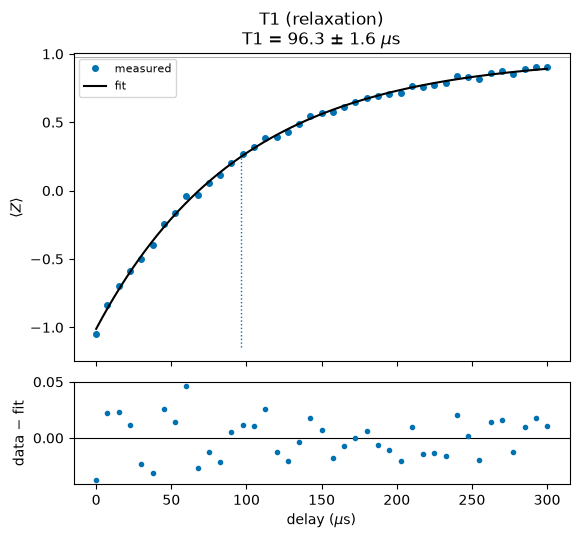

In [6]:
fits = analysis.fit_all(data)
analysis.plot_single("t1", data["experiments"]["t1"], fits["t1"]);

There are two ways to see what the fit does.

- **Left, a straight line.** Remove the fitted $A$ and $B$ from the data, and what is left is $e^{-t/\tau}$. Its logarithm is a straight line with slope $-1/\tau$. This was the method before computers. It is a good check but a poor way to *fit*, because the logarithm turns small errors on small values into large ones.
- **Right, the cost.** The plot shows the sum of squared residuals (the quantity the fit minimizes) as the time constant is varied by hand. The best fit is the lowest point. A narrow minimum means the data pin down $\tau$ tightly; a flat one means many values fit about equally well. The gray band is the standard error from the covariance matrix.

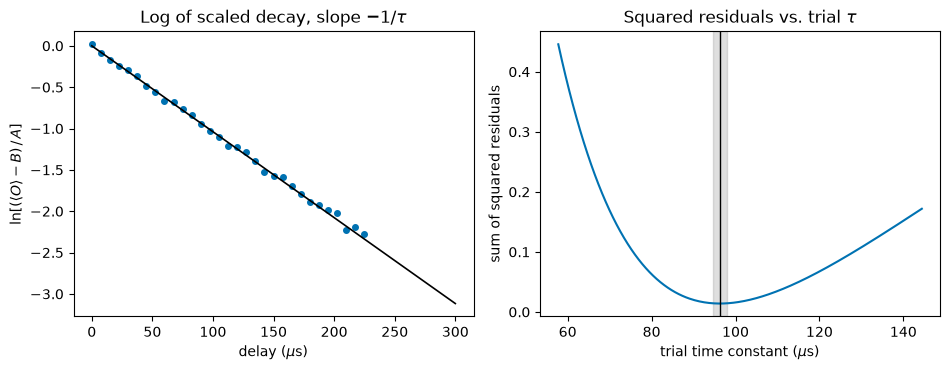

In [7]:
analysis.plot_checks("t1", data["experiments"]["t1"], fits["t1"]);

### T2\*: the Ramsey fringes

Now the phase. The curve oscillates at the detuning we programmed, 50 kHz, so one period is $20\,\mu$s. The envelope (dashed) is the decay we want, $e^{-t/T_2^*}$, and the oscillation inside it is only there to prove that phase is evolving. The fit has five parameters, so it is more sensitive to its starting guess than the others, which is why we start the frequency at the value we programmed.

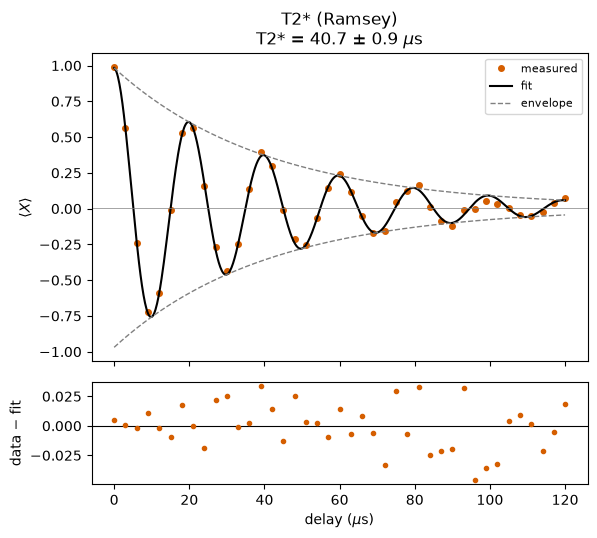

In [8]:
analysis.plot_single("t2star", data["experiments"]["t2star"], fits["t2star"]);

### T2: the Hahn echo

The same state, a flip in the middle of the wait. The oscillation is gone, because the programmed detuning and everything else constant is refocused, and what is left is a plain decay. Its time is longer than T2\*, because the slow noise no longer counts.

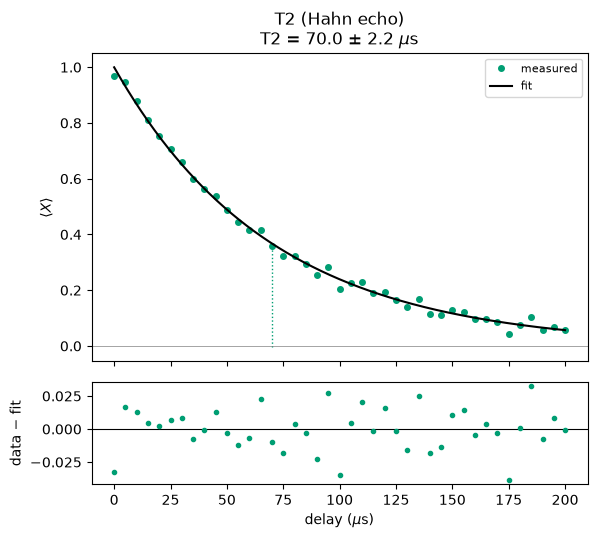

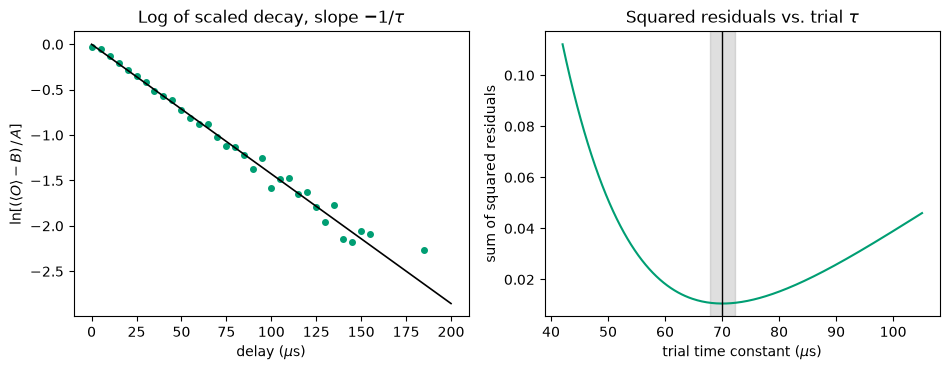

In [9]:
analysis.plot_single("t2", data["experiments"]["t2"], fits["t2"]);
analysis.plot_checks("t2", data["experiments"]["t2"], fits["t2"]);

### All three together

The table lists the fitted times with their standard errors. On the simulator it also shows the times that were built in, so the fit can be checked. $T_2^*$ is not one of the inputs of the noise model: it follows from the echo time and the slow noise, as $1/T_2^* = 1/T_2 + \gamma$, where $\gamma = 0.01\,\mu\text{s}^{-1}$ is the width of the slow noise.

                         fit (us)  built in (us)  amplitude
T1 (relaxation)       96.3 +/- 1.6           100.0      -1.99
T2* (Ramsey)          40.7 +/- 0.9            41.2       0.98
T2 (Hahn echo)        70.0 +/- 2.2            70.0       1.00

Ramsey fringe frequency: 50.2 kHz (programmed: 50.0 kHz)


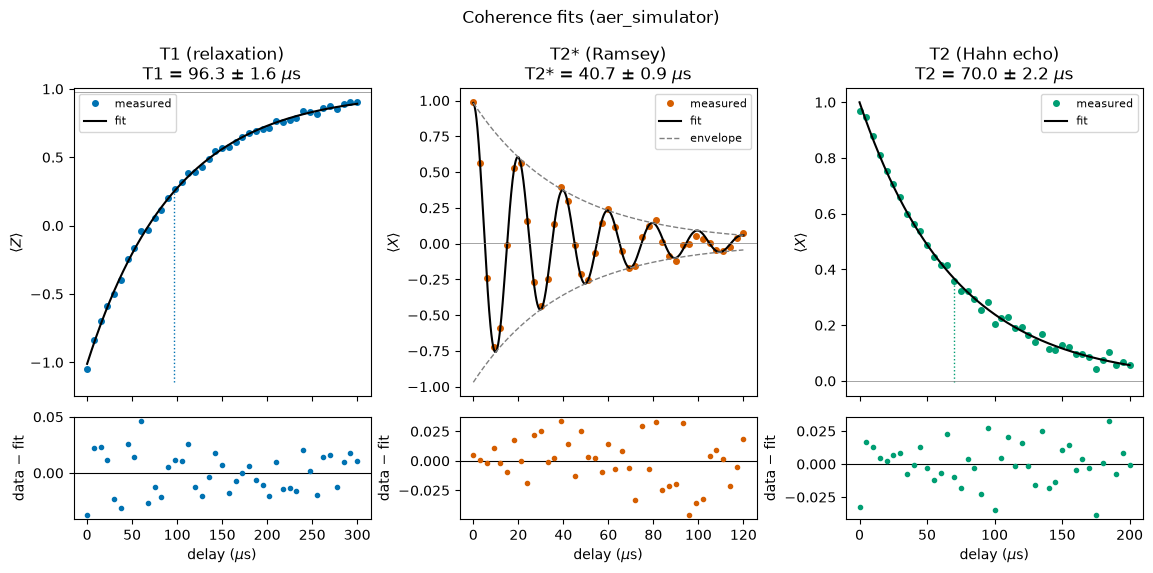

In [10]:
analysis.print_table(data, fits)
fig = analysis.plot_fits(data, fits)

The pure dephasing time follows from the three numbers, because the rates add:

$$\frac{1}{T_2} = \frac{1}{2T_1} + \frac{1}{T_\varphi}.$$

Half of the T1 rate is dephasing that comes only from the energy loss, and $T_\varphi$ is whatever is left over. It tells you how much a qubit would gain if its relaxation could be improved, and how much would not change.

In [11]:
tau = {name: fits[name]["params"]["tau"] for name in fits}
err = {name: fits[name]["errors"]["tau"] for name in fits}

rate = 1 / tau["t2"] - 1 / (2 * tau["t1"])
rate_err = np.hypot(err["t2"] / tau["t2"] ** 2, err["t1"] / (2 * tau["t1"] ** 2))
print(f"T2* = {tau['t2star']:.1f} us <= T2 = {tau['t2']:.1f} us <= 2 T1 = {2 * tau['t1']:.1f} us")
print(f"pure dephasing time T_phi = {1 / rate:.0f} us "
      f"(1 sigma range {1 / (rate + rate_err):.0f} to {1 / max(rate - rate_err, 1e-9):.0f} us)")

T2* = 40.7 us <= T2 = 70.0 us <= 2 T1 = 192.5 us
pure dephasing time T_phi = 110 us (1 sigma range 105 to 116 us)


## Reading the results

The numbers below are for the simulator with the default settings. Noise is random, so a rerun changes them by about their standard errors.

- **T1 is about 100 $\mu$s**, and the fitted amplitude is about $-2$: the curve goes from $-1$ to $+1$ as the qubit falls from $|1\rangle$ to $|0\rangle$. The residuals are about $\pm0.02$, the precision we asked for.
- **T2\* is about 41 $\mu$s.** The fringes sit at 50 kHz and the envelope decays about twice as fast as the echo does.
- **T2 is about 70 $\mu$s.** The echo removed the slow noise, so the time is longer. This is the time you would expect a qubit to keep a superposition if you protect it with a flip.
- **The ordering holds**: $T_2^* < T_2 < 2T_1 = 200\,\mu$s. A fit that gives $T_2 > 2T_1$ would mean something is wrong with the measurement (a bad delay range, a fit that stopped at a poor value, or drift in the qubit between the experiments).
- **The simulator agrees with its own inputs** to within a few standard errors. A few percent is the accuracy of an experiment with 41 points and a precision of 0.02. A smaller error needs more points or more shots, and is limited by the length of the delay range: a curve that runs for only one $\tau$ cannot tell a time constant from the offset.

On hardware, expect more of the following:

- **A smaller $|A|$ and a $B$ away from its ideal value**, because the preparation and read-out are imperfect. These are error sources of a different kind: they do not grow with the delay, so the fit puts them in $A$ and $B$ and leaves $\tau$ alone.
- **A Ramsey frequency that differs from 50 kHz**, by the offset between the qubit's true frequency and the one the electronics assume.
- **T1 that changes from hour to hour.** The time is set by a few defects in the material, which move. Two measurements a day apart may not agree, and that is real.
- **A decay that is not exponential**, which shows up as structure in the residuals. Slow noise often gives a Gaussian-shaped Ramsey decay rather than an exponential one.

## What to try next

1. Change `t_max["t1"]` to `100.0` (one $T_1$) and then to `30.0`. How do the fitted $T_1$ and its error change? What does this say about choosing a delay range?
2. Set `points = 11`, then `101`. How does the standard error scale? Is it worth the extra circuits?
3. Set `precision = 0.1`, then `0.005`. Which gets the better error bar for the same number of circuits, more points or a smaller precision? (The simulator is fast enough to try.)
4. In `ops.py` change `GAMMA_SLOW` to `1 / 30` and rerun. What happens to T2\*, and what happens to T2?
5. Change `SIM_T2` to a value larger than `2 * SIM_T1`. What does the simulator do, and why can no real qubit do this?
6. Change `DETUNING` in `ops.py` to `0.5` (MHz) and rerun. The fringes are now faster than the spacing of the delays. What does the fit return, and what is this effect called?
7. Run on `ibm_rensselaer` with `qubit = 0`, then with a different qubit. Do the qubits agree? Compare with the T1 and T2 values on the backend's calibration page. Which of your numbers is closest, and why might the page differ from your measurement?
8. Run T1 three times in a row on hardware and compare the results. How big is the spread compared with the standard error of one fit?
9. A superposition lives for $T_2$, but the algorithms in Unit 2 run many gates. Take the depth of a circuit from Unit 2 and the duration of one gate (look up `backend.target`). What fraction of $T_2$ does the circuit use?